# 01. Exploring the data and checking for leakage

## 1. Objective
Understand the Home Credit data, its quality problems, and prove (as far as possible) that the pipeline is free of leakage before modelling.

## 2. Data
Kaggle *Home Credit Default Risk*: `application_train` (307,511 x 122), `application_test` (48,744), plus six history tables. The raw files are not committed (competition data); download them from Kaggle into `data/raw/`. This notebook only reads the saved summary tables.

In [1]:
import sys, json, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 30)
T = '../outputs/tables/'; F = '../outputs/figures/'

In [2]:
s = json.load(open('../outputs/eda_summary.json'))
print({k: s[k] for k in ['n_rows', 'n_cols', 'default_rate', 'cols_with_missing', 'cols_over_50pct_missing']})

{'n_rows': 307511, 'n_cols': 122, 'default_rate': 0.08072881945686496, 'cols_with_missing': 67, 'cols_over_50pct_missing': 41}


## 3. Target and class imbalance
Only about 8% of applicants default.

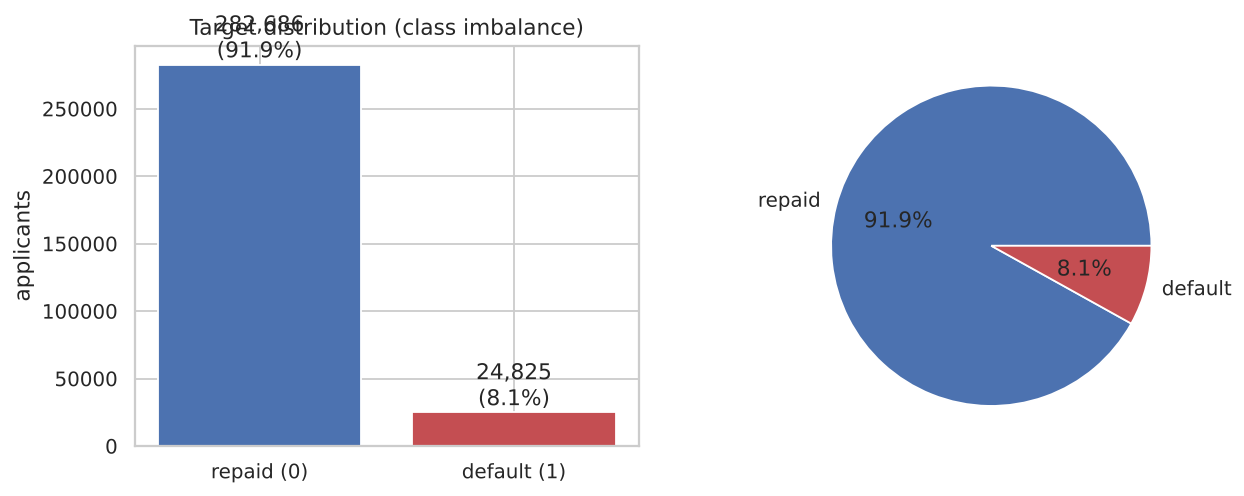

In [3]:
display(Image(F + '01_target_distribution.png'))

A model that always predicts 'repays' is 91.9% accurate and worthless, so accuracy is the wrong metric. We use AUC, precision-recall and lift.

## 4. Missing values

,missing_pct,dtype
COMMONAREA_AVG,69.9,float32
COMMONAREA_MODE,69.9,float32
COMMONAREA_MEDI,69.9,float32
NONLIVINGAPARTMENTS_MEDI,69.4,float32
NONLIVINGAPARTMENTS_MODE,69.4,float32
NONLIVINGAPARTMENTS_AVG,69.4,float32
FONDKAPREMONT_MODE,68.4,str
LIVINGAPARTMENTS_AVG,68.4,float32
LIVINGAPARTMENTS_MEDI,68.4,float32
LIVINGAPARTMENTS_MODE,68.4,float32


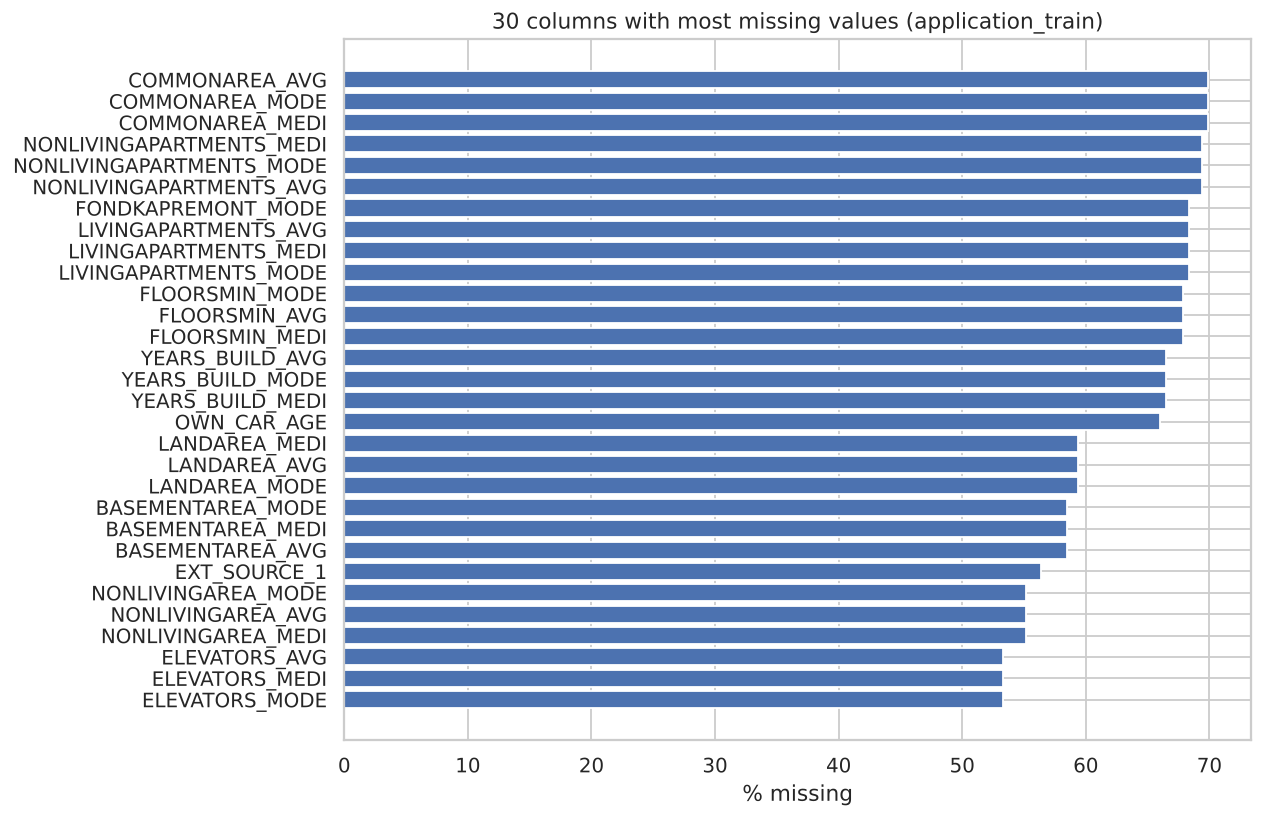

In [4]:
m = pd.read_csv(T + '01_missing_value_summary.csv', index_col=0); display(m.head(12).round(1)); display(Image(F + '02_missing_values_top30.png'))

41 columns are more than half empty (housing details, building characteristics). Trees can use 'missing' as a branch, so we keep them; the logistic regression baseline imputes with the median.

## 5. A data trap: `DAYS_EMPLOYED = 365243`

In [5]:
print('share of rows with the code 365243:', round(s['days_employed_sentinel_share'], 3)); print('default rate when code present / absent:', s['default_rate_sentinel'])

share of rows with the code 365243: 0.18
default rate when code present / absent: {'False': 0.0865997453765215, 'True': 0.05399646043269404}


The value is not a real number of days; it marks pensioners and unemployed (also `ORGANIZATION_TYPE = 'XNA'`, same 18%). We replace it by NaN and add a flag.

## 6. Which variables relate to default?

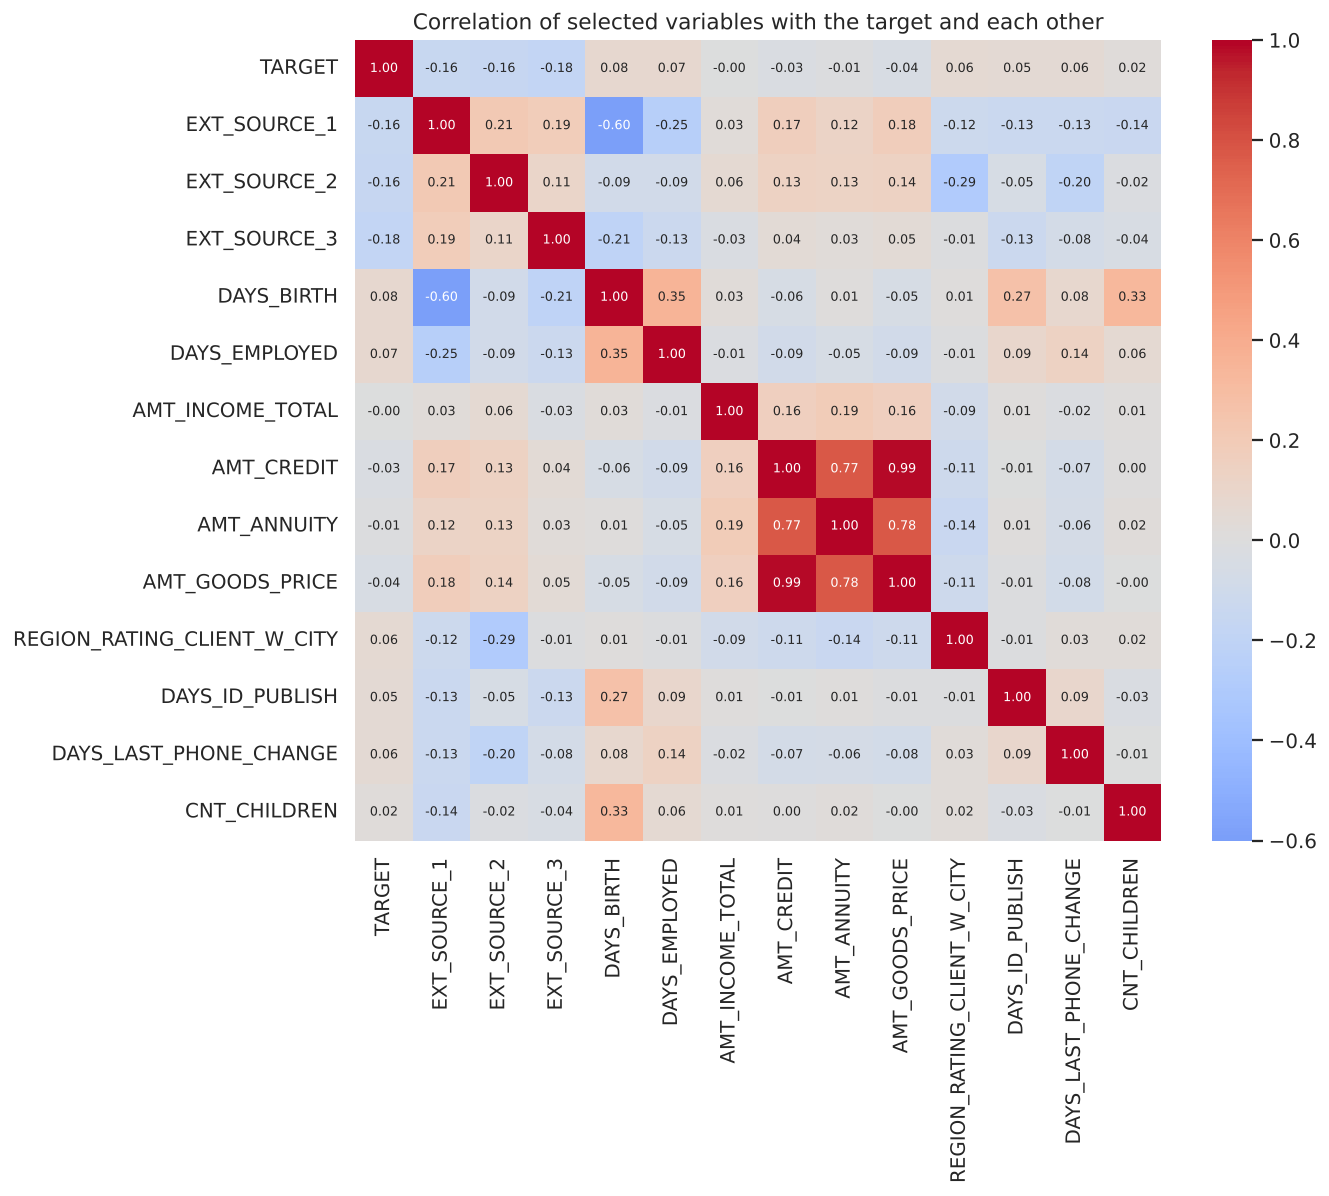

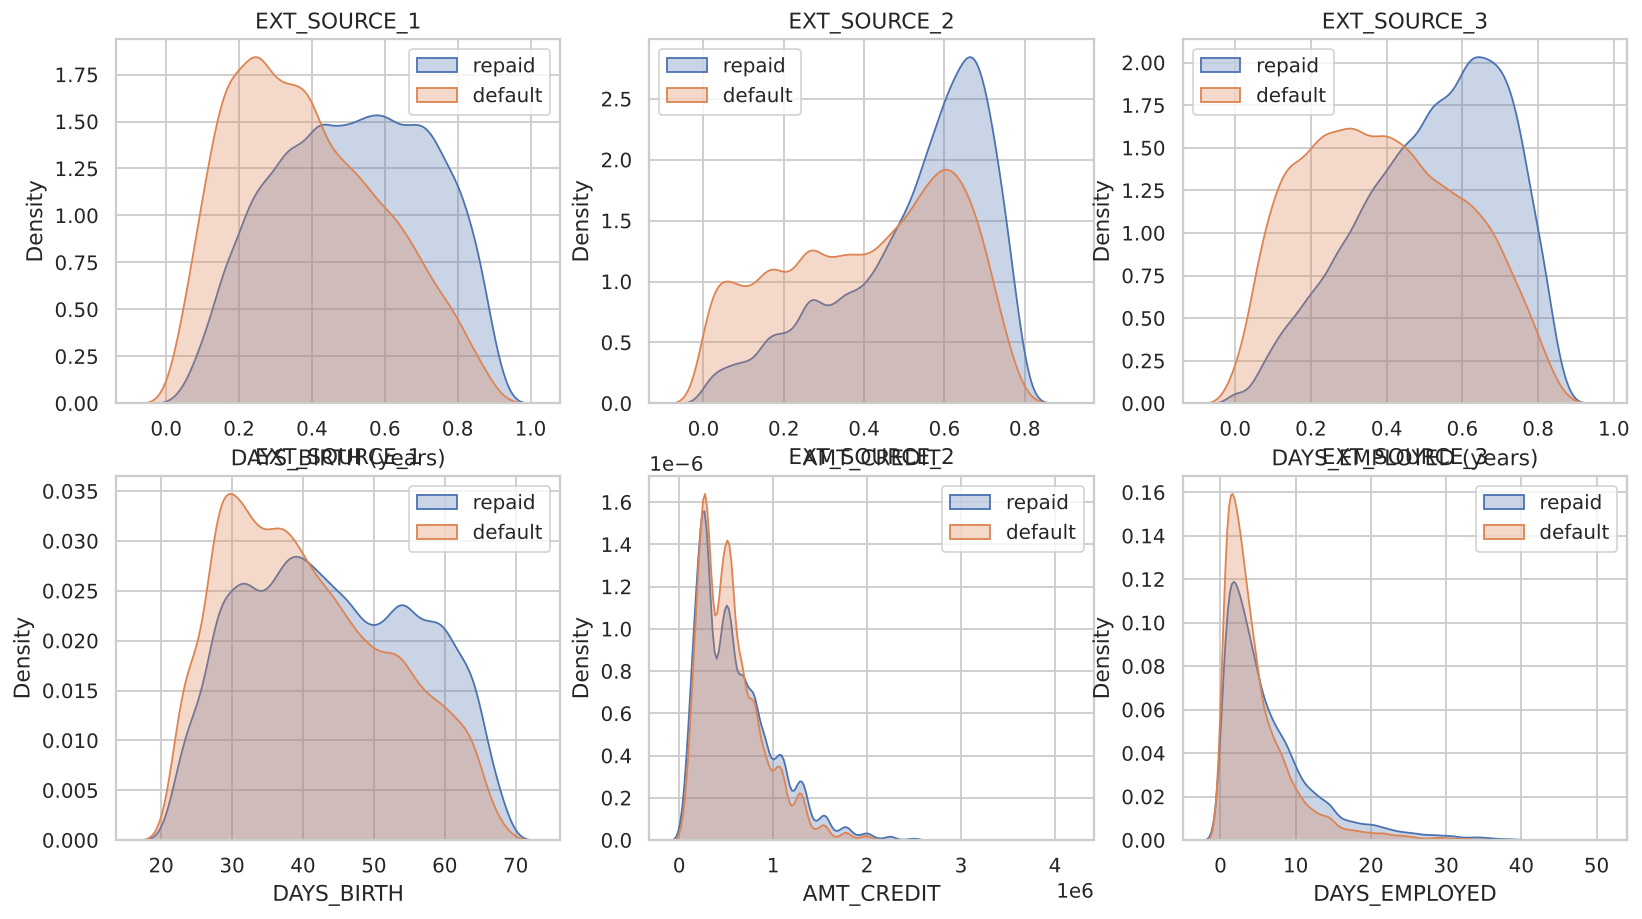

In [6]:
display(Image(F + '03_correlation_heatmap.png')); display(Image(F + '04_distributions_by_target.png'))

In [7]:
pd.read_csv(T + '02_correlation_with_target.csv', index_col=0).round(3)

,TARGET
EXT_SOURCE_3,-0.179
EXT_SOURCE_2,-0.160
EXT_SOURCE_1,-0.155
AMT_GOODS_PRICE,-0.040
AMT_CREDIT,-0.030
AMT_ANNUITY,-0.013
AMT_INCOME_TOTAL,-0.004
CNT_CHILDREN,0.019
DAYS_ID_PUBLISH,0.051
DAYS_LAST_PHONE_CHANGE,0.055


The three anonymous external scores (EXT_SOURCE_1/2/3) are the only variables with notable (negative) correlation: higher score, lower risk. Defaulters are younger and have shorter employment.

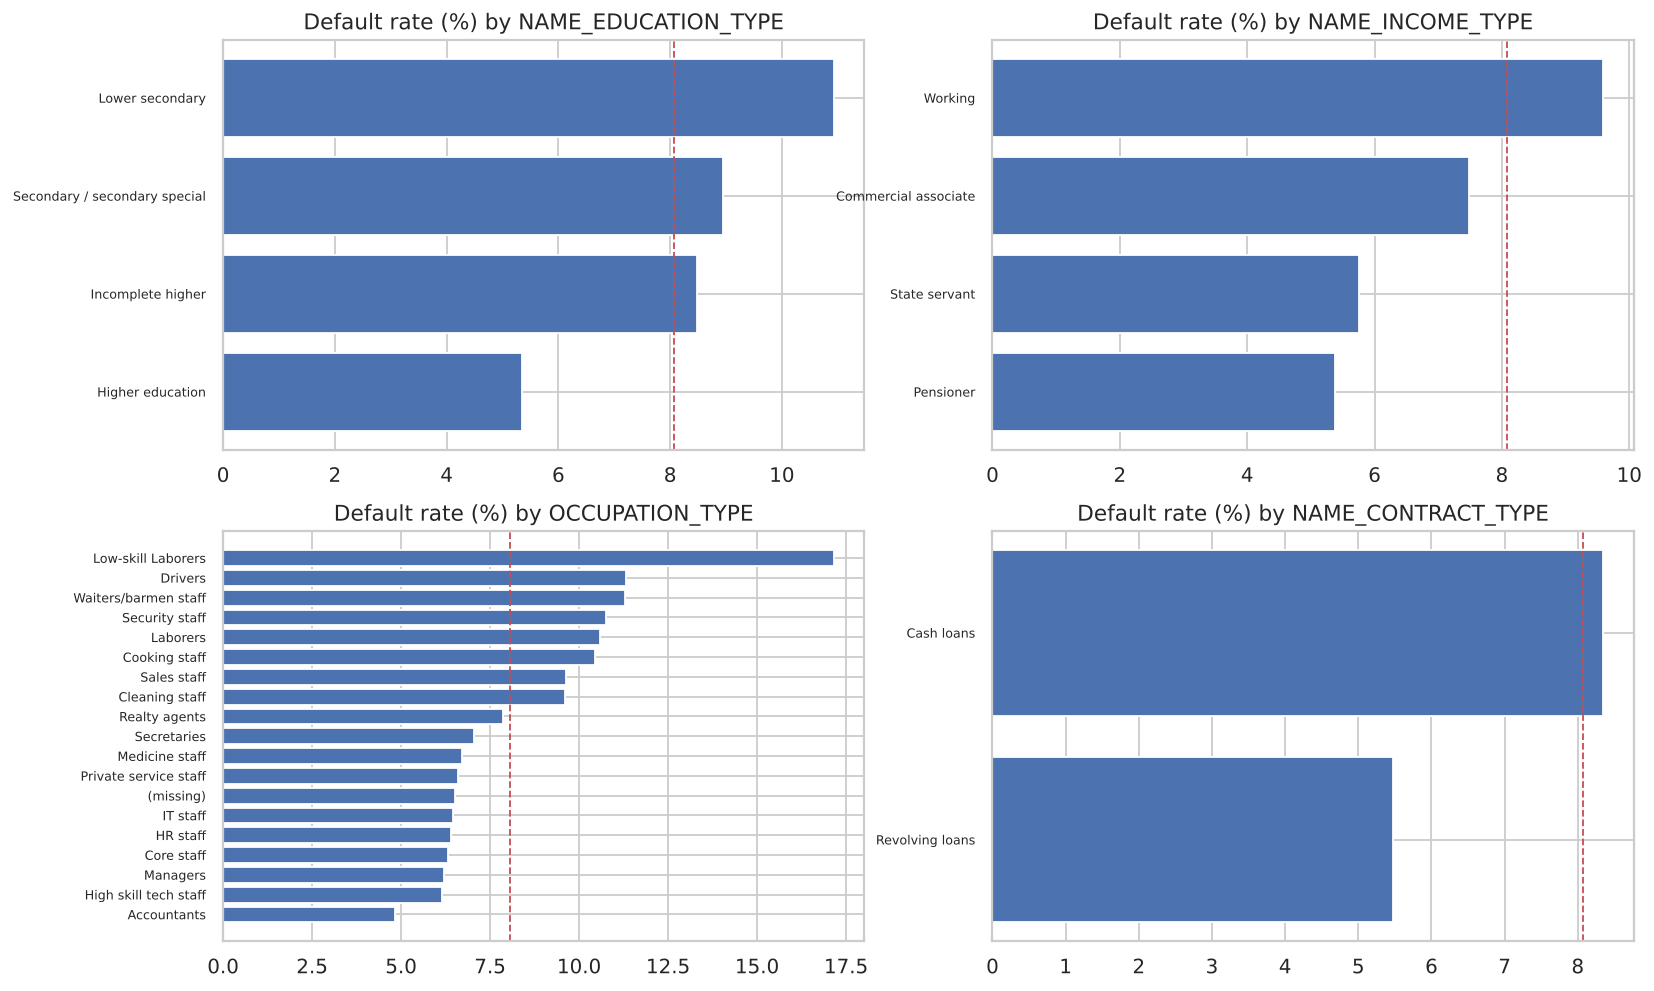

In [8]:
display(Image(F + '05_default_rate_by_category.png'))

## 7. Leakage check 1: single-feature AUC scan
If any single column predicts the target almost perfectly, it is probably a leak.

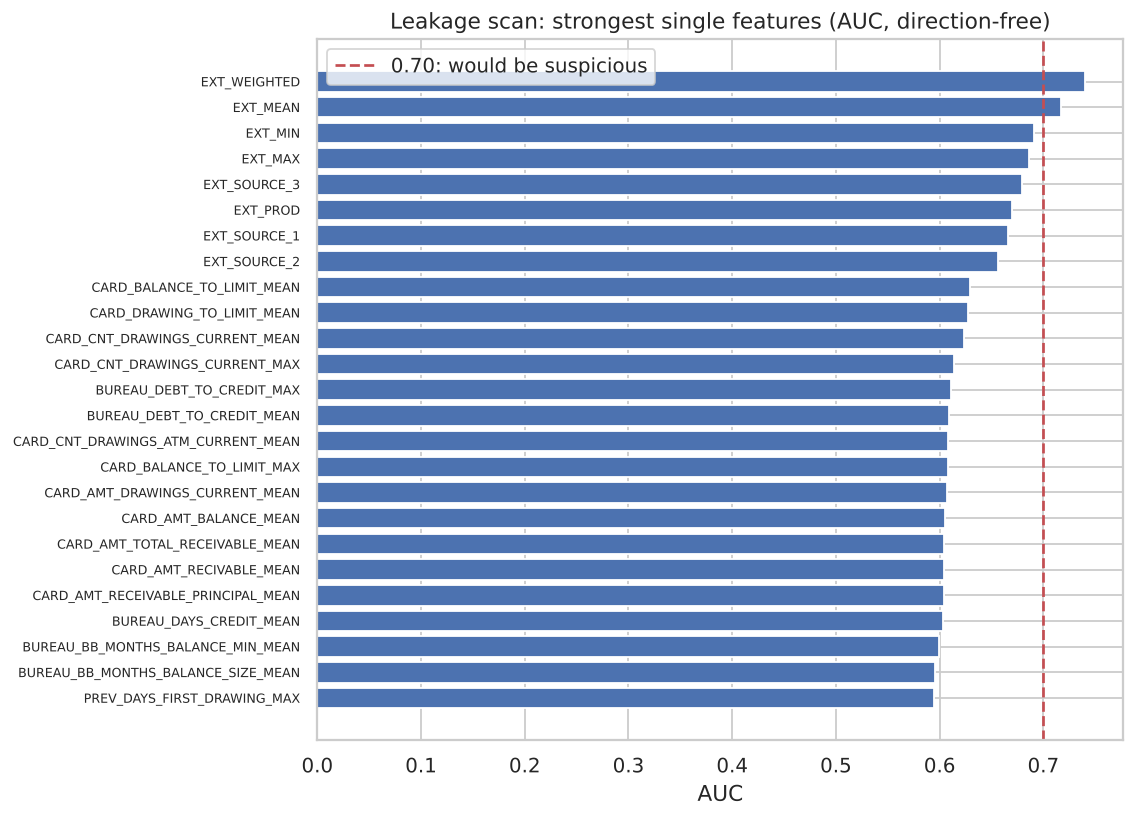

,feature,auc,strength,coverage
0,EXT_WEIGHTED,0.260,0.740,0.356
1,EXT_MEAN,0.283,0.717,0.999
2,EXT_MIN,0.309,0.691,0.999
3,EXT_MAX,0.314,0.686,0.999
4,EXT_SOURCE_3,0.321,0.679,0.802
5,EXT_PROD,0.330,0.670,1.000
6,EXT_SOURCE_1,0.334,0.666,0.436
7,EXT_SOURCE_2,0.344,0.656,0.998
8,CARD_BALANCE_TO_LIMIT_MEAN,0.629,0.629,0.278
9,CARD_DRAWING_TO_LIMIT_MEAN,0.628,0.628,0.270


In [9]:
display(Image(F + '06_single_feature_auc_scan.png')); pd.read_csv(T + '04_single_feature_auc_scan.csv').head(10).round(3)

The strongest features are the external scores (about 0.68; combinations up to 0.74). Nothing is near 0.9, so there is no obvious leak.

## 8. Leakage checks 2 and 3: ID and shuffled target

In [10]:
print('AUC of SK_ID_CURR alone:', round(s['auc_of_SK_ID_CURR'], 3)); print('AUC with SHUFFLED labels (3-fold CV):', round(s['shuffled_target_cv_auc'], 3))

AUC of SK_ID_CURR alone: 0.498
AUC with SHUFFLED labels (3-fold CV): 0.498


Both are 0.50: the ID carries no information and, when the labels are randomly shuffled, the whole pipeline scores chance level, so it cannot be leaking the answer.

## 9. Adversarial validation: do train and test look alike?

In [11]:
print('adversarial AUC, raw application features:', round(s['adversarial_auc_set_A'], 3)); print('adversarial AUC, + engineered ratios:', round(s['adversarial_auc_set_B'], 3))
print('cash-loan share train / test:', [round(x, 3) for x in s['cash_loan_share_train_vs_test']]); print('mean credit train / test:', [round(x) for x in s['amt_credit_mean_train_vs_test']])
pd.read_csv(T + '05_adversarial_top_features_set_A.csv').head(6)

adversarial AUC, raw application features: 0.89
adversarial AUC, + engineered ratios: 0.947
cash-loan share train / test: [0.905, 0.991]
mean credit train / test: [599026, 516740]


,Unnamed: 0,gain_share
0,AMT_CREDIT,0.183913
1,AMT_ANNUITY,0.125146
2,AMT_REQ_CREDIT_BUREAU_QRT,0.113399
3,AMT_REQ_CREDIT_BUREAU_MON,0.106209
4,AMT_GOODS_PRICE,0.101634
5,NAME_CONTRACT_TYPE,0.049290


A classifier can tell training rows from test rows with AUC 0.89, driven by loan amount, bureau-enquiry counts and contract type. The official test set is **not a random sample** of the training set (99.1% cash loans vs 90.5%). So our cross-validation score estimates performance on training-like applicants and the Kaggle leaderboard score may differ.

**A bug this check found:** my first version of a 'number of missing values' feature also counted the empty `TARGET` column, which is empty on every test row; the adversarial AUC was 0.99. After the fix it fell to 0.95 (with engineered ratios) / 0.89 (raw). The fix is covered by a unit test.

## 10. Conclusion
The data have known quirks (sentinel values, heavy missingness), no sign of leakage in the training pipeline, and a genuine train/test shift that should be remembered when reading any score.